In [ ]:
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pathlib import Path
from solver.geometry import WingParameters, build_wing_geometry
from solver.vlm import solve_vlm_neuralfoil

# For path/directory troubleshooting (can delete later) ---------------------

project_path = Path.cwd().parent
sys.path.insert(0, str(project_path / "src"))

data_path = project_path / "data"
data_path.mkdir(exist_ok=True)

print("Solver found:", (project_path / "src" / "solver").is_dir())
print("Data will be saved in:", data_path)

# End of path/directory troubleshooting --------------------------------------

Solver found: True
Data will be saved in: c:\Users\jeffr\Downloads\Maching-Learning-Project-main\Maching-Learning-Project-main\data


In [ ]:
# Small trial dataset. Can be changed but will take long time, so I started with small set
aspect_ratios = [6.0, 8.0, 10.0]
angles_of_attack = [2.0, 5.0, 8.0]

total_samples = len(aspect_ratios) * len(angles_of_attack)


rows = []

for aspect_ratio in aspect_ratios:

    # Defines and builds wing
    parameters = WingParameters(
        aspect_ratio=aspect_ratio,
        area_m2=1.0,
        taper_ratio=0.5,
        sweep_deg=0.0,
        airfoil="naca0012"
    )

    geometry = build_wing_geometry(parameters)

    for alpha in angles_of_attack:

        # Calculates aerodynamic results
        result = solve_vlm_neuralfoil(
            geometry,
            velocity=100.0,
            alpha=alpha,
            spanwise_resolution=40,
            chordwise_resolution=4,
            lift_tolerance=1e-6
        )

        # Saves the inputs and outputs
        rows.append({
            "geometry_id": geometry.geometry_id,
            "aspect_ratio": aspect_ratio,
            "area_m2": 1.0,
            "taper_ratio": 0.5,
            "sweep_deg": 0.0,
            "airfoil": "naca0012",
            "velocity": 100.0,
            "alpha_deg": alpha,
            "CL": result["CL"],
            "CD_profile": result["CD_profile"],
            "max_lift_error": result["max_lift_error"],
            "runtime_s": result["total_runtime_s"]
        })

        # Saves after each successful case to preserve progress
        df = pd.DataFrame(rows)
        df.to_csv(data_path / "wing_data_trial.csv", index=False)

        print(
            f"Completed {len(rows)}/{total_samples}: "
            f"AR = {aspect_ratio}, alpha = {alpha}, "
            f"CL = {result['CL']:.4f}"
        )

df

Completed 1/9: AR = 6.0, alpha = 2.0, CL = 0.1584
Completed 2/9: AR = 6.0, alpha = 5.0, CL = 0.3959
Completed 3/9: AR = 6.0, alpha = 8.0, CL = 0.6268
Completed 4/9: AR = 8.0, alpha = 2.0, CL = 0.1728
Completed 5/9: AR = 8.0, alpha = 5.0, CL = 0.4303
Completed 6/9: AR = 8.0, alpha = 8.0, CL = 0.6832
Completed 7/9: AR = 10.0, alpha = 2.0, CL = 0.1824
Completed 8/9: AR = 10.0, alpha = 5.0, CL = 0.4523
Completed 9/9: AR = 10.0, alpha = 8.0, CL = 0.7226


,geometry_id,aspect_ratio,area_m2,taper_ratio,sweep_deg,airfoil,velocity,alpha_deg,CL,CD_profile,max_lift_error,runtime_s
0,wing_0fea48fba59253a479f3,6.0,1.0,0.5,0.0,naca0012,100.0,2.0,0.158375,0.005250,7.244205e-15,6.691710
1,wing_0fea48fba59253a479f3,6.0,1.0,0.5,0.0,naca0012,100.0,5.0,0.395948,0.005958,8.104628e-15,6.453341
2,wing_0fea48fba59253a479f3,6.0,1.0,0.5,0.0,naca0012,100.0,8.0,0.626846,0.007262,1.270650e-13,9.389478
3,wing_126480edad821890d75a,8.0,1.0,0.5,0.0,naca0012,100.0,2.0,0.172767,0.005278,9.547918e-15,15.957298
4,wing_126480edad821890d75a,8.0,1.0,0.5,0.0,naca0012,100.0,5.0,0.430345,0.006218,5.051515e-15,15.011072
5,wing_126480edad821890d75a,8.0,1.0,0.5,0.0,naca0012,100.0,8.0,0.683245,0.007829,7.094325e-14,13.348918
6,wing_31b59655fcb0b9e67269,10.0,1.0,0.5,0.0,naca0012,100.0,2.0,0.182365,0.005312,2.266243e-14,13.301618
7,wing_31b59655fcb0b9e67269,10.0,1.0,0.5,0.0,naca0012,100.0,5.0,0.452315,0.006432,1.060263e-14,14.056770
8,wing_31b59655fcb0b9e67269,10.0,1.0,0.5,0.0,naca0012,100.0,8.0,0.722564,0.008299,8.548717e-15,16.252690


# Plots for Data Visualization

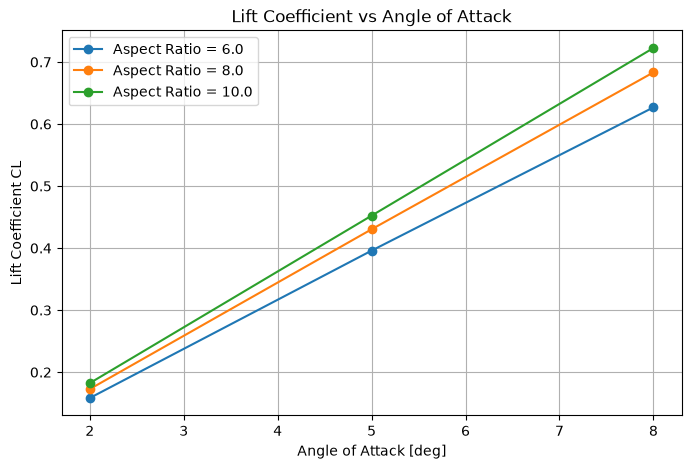

In [5]:
plt.figure(figsize=(8, 5))

for aspect_ratio in aspect_ratios:

    temp = df[df["aspect_ratio"] == aspect_ratio]

    plt.plot(
        temp["alpha_deg"],
        temp["CL"],
        "o-",
        label=f"Aspect Ratio = {aspect_ratio}"
    )

plt.xlabel("Angle of Attack [deg]")
plt.ylabel("Lift Coefficient CL")
plt.title("Lift Coefficient vs Angle of Attack")
plt.legend()
plt.grid()
plt.show()

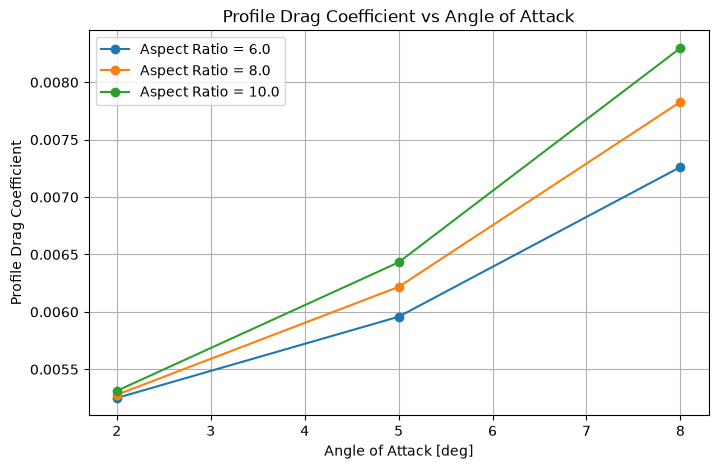

In [ ]:
plt.figure(figsize=(8, 5))

for aspect_ratio in aspect_ratios:

    temp = df[df["aspect_ratio"] == aspect_ratio]

    plt.plot(
        temp["alpha_deg"],
        temp["CD_profile"],
        "o-",
        label=f"Aspect Ratio = {aspect_ratio}"
    )

plt.xlabel("Angle of Attack [deg]")
plt.ylabel("Profile Drag Coefficient")
plt.title("Profile Drag Coefficient vs Angle of Attack")
plt.legend()
plt.grid()
plt.show()

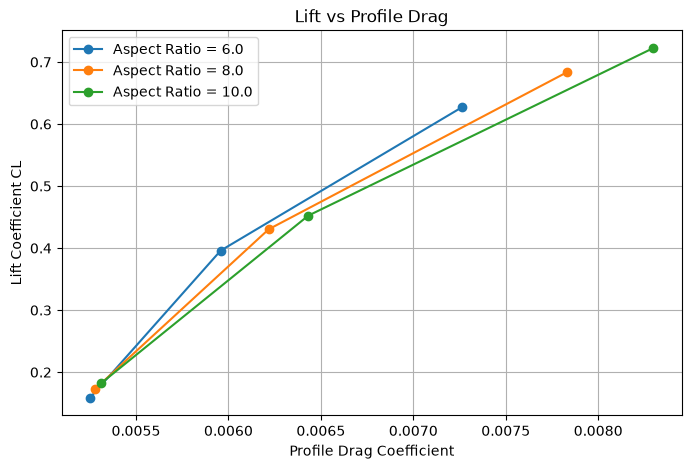

In [8]:
plt.figure(figsize=(8, 5))

for aspect_ratio in aspect_ratios:

    temp = df[df["aspect_ratio"] == aspect_ratio]
    temp = temp.sort_values("alpha_deg")

    plt.plot(
        temp["CD_profile"],
        temp["CL"],
        "o-",
        label=f"Aspect Ratio = {aspect_ratio}"
    )

plt.xlabel("Profile Drag Coefficient")
plt.ylabel("Lift Coefficient CL")
plt.title("Lift vs Profile Drag")
plt.legend()
plt.grid()
plt.show()